In [1]:
# %load_ext autoreload
# %autoreload 2
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent.parent.parent.parent.parent
sys.path.insert(0, str(PROJECT_ROOT))
print(PROJECT_ROOT)
from src.inference import generate, encode_cells, get_latent_mean, get_mean, load_data, load_model, sample_around_point, calc_r2_pearson

import scanpy as sc
import os
import anndata
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.pyplot import rc_context
import anndata
import seaborn as sns
import torch
import torch
import torch.distributed as dist
from torch.nn.parallel import DistributedDataParallel as DDP
import scipy.sparse as sp
print("CUDA Available: ", torch.cuda.is_available())
print("Number of GPUs: ", torch.cuda.device_count())
from matplotlib import font_manager
font_manager.fontManager.addfont("../../../arial.ttf")
plt.rcParams["font.family"] = "Arial"
plt.rcParams.update({
    "font.family": "Arial",
    "font.size": 18,
    "pdf.fonttype": 42,       # Embed TrueType fonts in PDF
})


/lustre/work/yaolab/mzhou10/squidiff_practice/Squidiff/project_v3
CUDA Available:  True
Number of GPUs:  1


In [2]:
# data = sc.read_h5ad("../input/plant_paper_test_day21_adata.h5ad")

# X = data.X

# if sp.issparse(X):
#     print("min:", X.min())
#     print("max:", X.max())
#     print("mean",X.mean())
#     # Count values below 0
#     below_0 = np.sum(X.data < 0)

#     # Count values below 0.01
#     # Important: sparse matrix has many hidden zeros.
#     # Since 0 < 0.01, all hidden zeros should be counted.
#     total_values = X.shape[0] * X.shape[1]
#     above_or_equal_001 = X.multiply(X >= 0.01).count_nonzero()
#     below_001 = total_values - above_or_equal_001

#     print("total", total_values)
#     print("below 0:", below_0)
#     print("below 0.01:", below_001)
#     print("below 0.01:", below_001 / total_values)

# # else:
# #     print("min:", np.min(X))
# #     print("max:", np.max(X))
# #     print("mean",np.mean(X))
# #     print("below 0:", np.sum(X < 0))
# #     print("below 0.01:", np.sum(X < 0.01))

In [3]:
# data = sc.read_h5ad("../input/plant_experiment1_train_adata.h5ad")
# # data = sc.read_h5ad("../input/plant_paper_test_day21_adata.h5ad")
# # data = sc.read_h5ad("../input/plant_all_days.h5ad")
# # print(print(adata[:5, :10].to_df()))
# # Convert to dense numpy array regardless of sparse/dense format

# X = data.X
# # print(X)
# # X = data.X.toarray() if sp.issparse(data.X) else np.asarray(data.X)
# # print(X.size)
# # X = X.astype(np.float32)

# print(X.shape)
# print(X.shape[0] * X.shape[1])
# total = X.shape[0] * X.shape[1]
# print(total)

# nan_count = np.isnan(X.data).sum()
# print("nan:", nan_count)

In [4]:

# data = sc.read_h5ad("../input/plant_paper_test_day21_adata.h5ad")
# # data = sc.read_h5ad("../input/plant_all_days.h5ad")
# # print(print(adata[:5, :10].to_df()))
# # Convert to dense numpy array regardless of sparse/dense format

# X = data.X
# # print(X)
# # X = data.X.toarray() if sp.issparse(data.X) else np.asarray(data.X)
# # print(X.size)
# # X = X.astype(np.float32)

# print(X.shape)
# print(X.shape[0] * X.shape[1])
# total = X.shape[0] * X.shape[1]
# print(total)
# print("min:", np.min(X))
# print("max:", np.max(X))
# print("mean:", np.mean(X))
# print("below 0:", np.sum(X < 0))
# print("below 0:", np.sum(X < 0)/total)
# print("below 0.1:", np.sum(X < 0.1))
# print("below 0.1:", np.sum(X < 0.1)/total)

# print("equals 0:", np.sum(X == 0))
# print("equals 0:", np.sum(X == 0)/total)
# print("below 18:", np.sum(X < 18))
# print("below 18:", np.sum(X < 18)/total)
# nan_count = np.isnan(X.data).sum()
# print("nan:", nan_count)

In [5]:
import scipy.sparse as sp
import numpy as np
adata = sc.read_h5ad("../experiments/plants_experiment1_predict_day21/interception_predict_to_day_21.h5ad")
print(adata)
# print(adata[:5, :10].to_df())
X = adata.X
print(X.size)

print(X.shape)
print(X.shape[0] * X.shape[1])
total = X.shape[0] * X.shape[1]
print("min:", np.min(X))
print("max:", np.max(X))
print("mean:", np.mean(X))
print("below 0:", np.sum(X < 0))
print("below 0:", np.sum(X < 0)/total)
print("below 0.1:", np.sum(X < 0.1))
print("below 0.1:", np.sum(X < 0.1)/total)
print("equals 0:", np.sum(X == 0))
print("equals 0:", np.sum(X == 0)/total)
print("below 18:", np.sum(X < 18))
print("below 18:", np.sum(X < 18)/total)
nan_count = np.isnan(X.data).sum()
print("nan:", nan_count)


AnnData object with n_obs × n_vars = 2401 × 39337
94448137
(2401, 39337)
94448137
min: 0.0
max: 25.94957
mean: 0.055365954
below 0: 0
below 0: 0.0
below 0.1: 80653059
below 0.1: 0.8539401788306317
equals 0: 30772638
equals 0: 0.3258151931572774
below 18: 94448068
below 18: 0.9999992694403279
nan: 0


In [6]:
# test_data_12 = sc.read_h5ad("../input/plant_paper_test_day12_adata.h5ad")
# # print(len(test_data_12.obs["Cluster"].unique()))

# for i in range(15):
#     adata_i = test_data_12[test_data_12.obs["Cluster"].astype(str) == str(i)].copy()

#     print("Cluster", i, adata_i.shape, adata_i.obs["Cluster"].unique())

#     adata_i.write_h5ad(f"test_day12_plant_experiment1_cluster_{i}.h5ad")

In [7]:
# # predict_data = sc.read_h5ad("../experiments/plants_experiment1_predict_day21/interception_predict_to_day_21.h5ad")
# test_data_21 = sc.read_h5ad("../input/plant_paper_test_day21_adata.h5ad")
# print(test_data_21)

In [8]:
# # print(len(real_data.obs["Cluster"].unique()))

# for i in range(15):
#     adata_i = test_data_21[test_data_21.obs["Cluster"].astype(str) == str(i)].copy()

#     print("Cluster", i, adata_i.shape, adata_i.obs["Cluster"].unique())

#     adata_i.write_h5ad(f"test_day21_plant_experiment1_cluster_{i}.h5ad")

0.957751437350377 0.9793201761316896


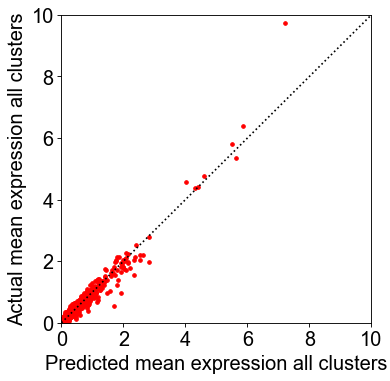

In [9]:

from src.inference import generate, encode_cells, get_latent_mean, get_mean, load_data, load_model, sample_around_point, calc_r2_pearson
r_all = []
pearsonr_all = []
# print(predict_data)
# print(real_data)

# real_data_x = real_data.X if isinstance(real_data.X, np.ndarray) else real_data.X.toarray()
# real_data_tensor = torch.tensor(real_data_x, dtype=torch.float32)
# predict_data_x = predict_data.X if isinstance(predict_data.X, np.ndarray) else predict_data.X.toarray()
# predict_data_tensor = torch.tensor(predict_data_x, dtype=torch.float32)
# print(real_data_tensor.shape)
# print(predict_data_tensor.shape)
# print(real_data.shape)
predict_data = sc.read_h5ad("../experiments/plants_experiment1_predict_day21/interception_predict_to_day_21.h5ad")
real_data = sc.read_h5ad("../../inputs/plant_paper_test_day21_adata.h5ad")

r2, pearsonr,real,predict = calc_r2_pearson(real_data,predict_data)
print(r2, pearsonr)

# r2_new, pearson_new = calc_r2_pearson(predict_data, real_data)
# print(r2_new, pearson_new)
r_all.append(['new method', "whole", 'predict day21 from test data day12', 'predict number:', predict_data.shape[0], 'test_data_number:',real_data.shape[0], 'r2_score:',r2])
pearsonr_all.append(['new method', "whole", 'predict day21 from test data day12', 'predict number:', predict_data.shape[0], 'test_data_number:',real_data.shape[0], 'pearson_score:',pearsonr])

# pd.DataFrame(r_all).to_csv(os.path.join("new_method_r_all_new.csv"))
# pd.DataFrame(pearsonr_all).to_csv(os.path.join("new_method_pearsonr_all_new.csv"))

fig, ax = plt.subplots(1,1,figsize=(5,5),dpi=80)
plt.scatter(predict,
            real,
             s=10,
             c='red'
           )
limit = np.ceil(max(np.max(predict), np.max(real)))
plt.xlim([0, limit])
plt.ylim([0, limit])
if limit <= 8:
  plt.xticks(np.arange(0, limit + 1, 1))
  plt.yticks(np.arange(0, limit + 1, 1)) 
else:    
  plt.xticks(np.arange(0, limit + 1, 2))
  plt.yticks(np.arange(0, limit + 1, 2))
plt.plot([0, limit], [0, limit], color="black", linestyle=":")
plt.xlabel("Predicted mean expression all clusters")
plt.ylabel("Actual mean expression all clusters")
fig.savefig(os.path.join(f"pred_with_actual_exp1_flexible_all_cluster.pdf"), bbox_inches="tight")


# cal = calc_r2_pearson(adata_day2_predicted, adata_day2_actual)
# print(f'CAL metric: {cal}')

0 0.8104958160598801 0.9129129317203762
10.7644415 21.482143
max 21.482143
cluster 0 done
1 0.7296827075278114 0.8745913092619932
8.684656 4.2194448
max 8.684656
cluster 1 done
2 0.8355216841232026 0.9156429873374273
5.3708253 4.1046133
max 5.3708253
cluster 2 done
3 0.705273965996243 0.8701835077236588
4.432476 3.8844335
max 4.432476
cluster 3 done
4 0.7541701722110352 0.8815121238712178
5.682375 4.2332034
max 5.682375
cluster 4 done
5 0.7458759657784059 0.8841311893156457
5.150333 3.8949158
max 5.150333
cluster 5 done
6 0.2681144824964713 0.5407151790613823
7.382323 3.998263
max 7.382323
cluster 6 done
7 0.6415212371935433 0.8610647869106774
12.799557 12.8131485
max 12.8131485
cluster 7 done
8 0.7933202723220734 0.8952865586664175
4.689107 4.144558
max 4.689107
cluster 8 done
9 0.8366770756647226 0.9160822322349006
4.6865444 4.216074
max 4.6865444
cluster 9 done
10 0.6086315376146412 0.8141304087392985
5.088023 4.0117373
max 5.088023
cluster 10 done
12 0.8109160964977139 0.9013877084

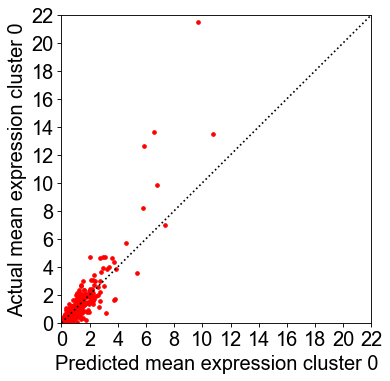

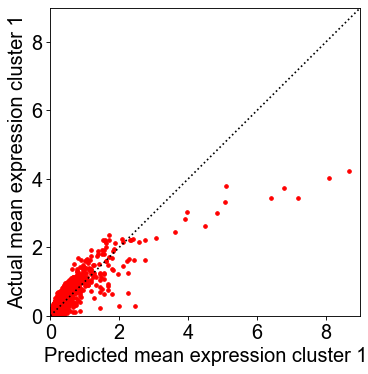

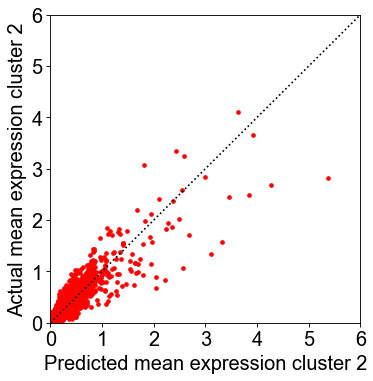

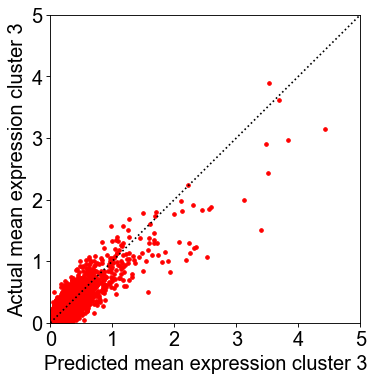

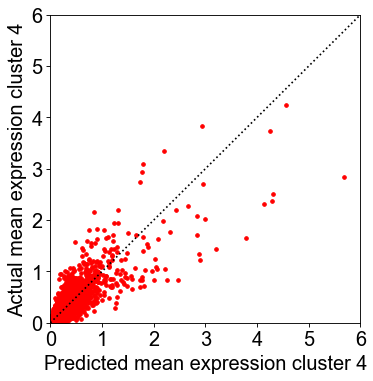

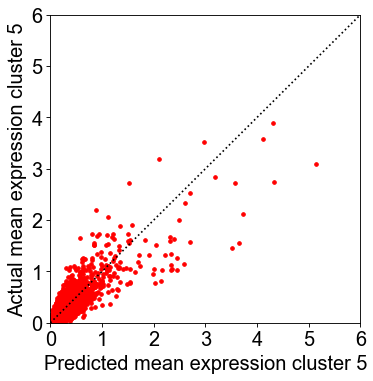

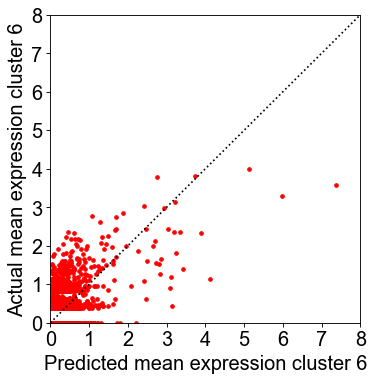

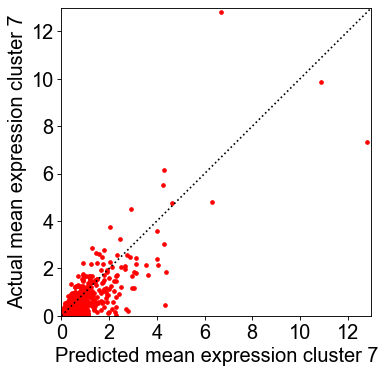

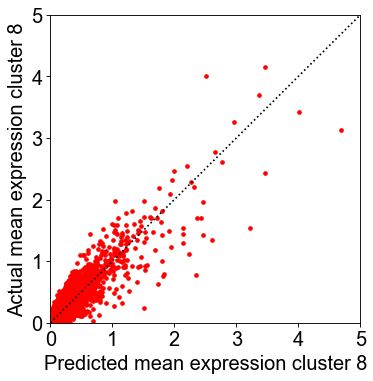

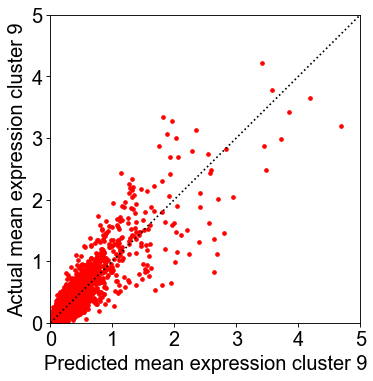

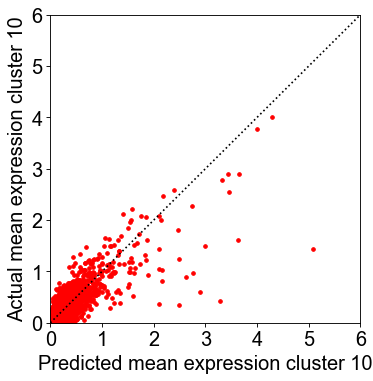

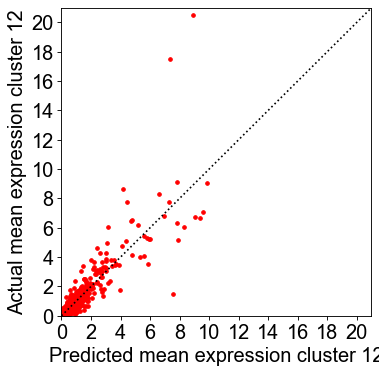

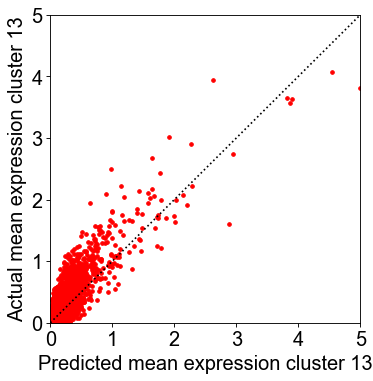

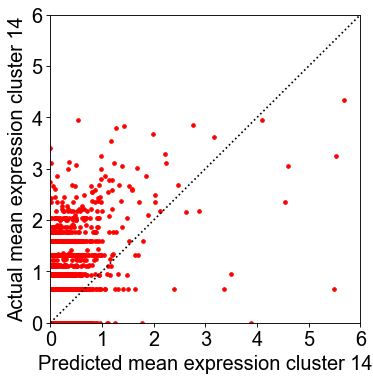

In [10]:

from src.inference import generate, encode_cells, get_latent_mean, get_mean, load_data, load_model, sample_around_point, calc_r2_pearson
# r_all = []
# pearsonr_all = []
# print(predict_data)
# print(real_data)

# real_data_x = real_data.X if isinstance(real_data.X, np.ndarray) else real_data.X.toarray()
# real_data_tensor = torch.tensor(real_data_x, dtype=torch.float32)
# predict_data_x = predict_data.X if isinstance(predict_data.X, np.ndarray) else predict_data.X.toarray()
# predict_data_tensor = torch.tensor(predict_data_x, dtype=torch.float32)
# print(real_data_tensor.shape)
# print(predict_data_tensor.shape)
# print(real_data.shape)
for i in range(15):
  if i ==11:
    continue
  real_data = sc.read_h5ad(f"../../inputs/test_day21_plant_experiment1_cluster_{i}.h5ad")
  predict_data = sc.read_h5ad(f"../experiments/plants_experiment1_predict_day21_cluster{i}/interception_predict_to_day_21.h5ad")
  r2, pearsonr,real,predict = calc_r2_pearson(real_data,predict_data)
  print(i, r2, pearsonr)
  # r2_new, pearson_new = calc_r2_pearson(predict_data, real_data)
  # print(r2_new, pearson_new)
  r_all.append(['new method', f"cluster{i}", 'predict day21 from test data day12', 'predict number:', predict_data.shape[0], 'test_data_number:',real_data.shape[0], 'r2_score:',r2])
  pearsonr_all.append(['new method', f"cluster{i}", 'predict day21 from test data day12', 'predict number:', predict_data.shape[0], 'test_data_number:',real_data.shape[0], 'pearson_score:',pearsonr])


  pd.DataFrame(r_all).to_csv(os.path.join("our_method_plant_exp1_r_all.csv"))
  pd.DataFrame(pearsonr_all).to_csv(os.path.join("our_method_plant_exp1_pearsonr_all.csv"))

  fig, ax = plt.subplots(1,1,figsize=(5,5),dpi=80)
  plt.scatter(predict,
              real,
              s=10,
              c='red'
            )
  limit = np.ceil(max(np.max(predict), np.max(real)))
  print(np.max(predict),np.max(real))
  plt.plot([0, limit], [0, limit], color="black", linestyle=":")
  plt.xlim([0, limit])
  plt.ylim([0, limit])
  if limit <= 8:
    plt.xticks(np.arange(0, limit + 1, 1))
    plt.yticks(np.arange(0, limit + 1, 1)) 
  else:    
    plt.xticks(np.arange(0, limit + 1, 2))
    plt.yticks(np.arange(0, limit + 1, 2))
  print("max",max(np.max(predict), np.max(real)))
  
  plt.xlabel(f"Predicted mean expression cluster {i}")
  plt.ylabel(f"Actual mean expression cluster {i}")
  print(f"cluster {i} done")
  fig.savefig(os.path.join(f"pred_with_actual_exp1_flexible_cluster_{i}.pdf"), bbox_inches="tight")
  # fig.savefig(os.path.join("fig2.png"), bbox_inches="tight")

# cal = calc_r2_pearson(adata_day2_predicted, adata_day2_actual)
# print(f'CAL metric: {cal}')